# Random Forest benchmark (Fischer & Krauss, 2018)

## 1. Setup and configuration

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)

warnings.filterwarnings("ignore", category=FutureWarning)

# Set this to your project folder if auto-detection fails (for example on Google Colab).
PROJECT_ROOT_OVERRIDE = None


def find_project_root():
    """Walk up from the working directory until data/processed/price_panel.csv is found."""
    if PROJECT_ROOT_OVERRIDE is not None:
        return Path(PROJECT_ROOT_OVERRIDE)
    here = Path.cwd().resolve()
    for p in [here, *here.parents][:6]:
        if (p / "data" / "processed" / "price_panel.csv").exists():
            return p
    raise RuntimeError(
        f"Could not find data/processed/price_panel.csv starting from {Path.cwd()}. "
        "Set PROJECT_ROOT_OVERRIDE to your project folder.")


ROOT = find_project_root()
PROCESSED_DIR = ROOT / "data" / "processed"
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Rolling-window design, identical to 02 and 03 (Fischer & Krauss 2018, Sec. 3.1)
TRAIN_DAYS = 750
TRADE_DAYS = 250
VALIDATION_FRACTION = 0.20

# 31 cumulative-return features, identical to 02 and 03 (Sec. 3.4)
CUMULATIVE_RETURN_HORIZONS = list(range(1, 21)) + list(range(40, 241, 20))
assert len(CUMULATIVE_RETURN_HORIZONS) == 31, "Expected 31 horizons"
FEATURE_COLS = [f"ret_{m}d" for m in CUMULATIVE_RETURN_HORIZONS]

# Random Forest hyperparameters (Fischer & Krauss 2018)
SEED = 42
RF_PARAMS = dict(n_estimators=1000, max_depth=20, max_features="sqrt",
                 bootstrap=True, criterion="gini", n_jobs=-1)

# Trading strategy, identical to 03
K_LONG_SHORT = 10
TRADING_DAYS = 252
PAPER_COST_PER_DAY = 4 * 0.0005   # 20 bps/day (2 legs x 2 half-turns, full turnover), as in 03

print(f"Project root: {ROOT}")
print(f"Features: {len(FEATURE_COLS)} | windows {TRAIN_DAYS}/{TRADE_DAYS} | K = {K_LONG_SHORT}")


Project root: C:\Users\sahar\OneDrive\Desktop\Deep-Learning-Financial-Forecasting-main
Features: 31 | windows 750/250 | K = 10


## 2. Load the price panel and build returns and targets (same as 02 and 03)

In [2]:
price_panel = pd.read_csv(PROCESSED_DIR / "price_panel.csv", index_col="date")
price_panel.index = pd.to_datetime(price_panel.index, format="mixed", dayfirst=True)

daily_returns = price_panel.pct_change()
forward_returns = daily_returns.shift(-1)     # realized next-day return, used by the backtest

next_day_returns = daily_returns.shift(-1)
daily_median = next_day_returns.median(axis=1)
targets = next_day_returns.ge(daily_median, axis=0).astype(float)
targets[next_day_returns.isna()] = np.nan

print(f"Price panel: {price_panel.shape[0]} dates x {price_panel.shape[1]} tickers "
      f"({price_panel.index.min().date()} to {price_panel.index.max().date()})")
print(f"Target class balance: {targets.stack().value_counts(normalize=True).round(3).to_dict()}")


Price panel: 6511 dates x 463 tickers (1990-01-02 to 2015-12-10)
Target class balance: {1.0: 0.509, 0.0: 0.491}


## 3. Precompute the 31 cumulative-return panels

In [3]:
cum_return_panels = {m: price_panel / price_panel.shift(m) - 1 for m in CUMULATIVE_RETURN_HORIZONS}
print(f"Precomputed {len(cum_return_panels)} cumulative-return panels.")


Precomputed 31 cumulative-return panels.


## 4. Rolling study periods (same generator as 02 and 03)

In [4]:
def generate_study_periods(dates, train_days=TRAIN_DAYS, trade_days=TRADE_DAYS):
    """Train on `train_days`, trade the next `trade_days`, then step forward by `trade_days`."""
    study_length = train_days + trade_days
    periods, start_idx, period_num = [], 0, 1
    while start_idx + study_length <= len(dates):
        train_end_idx = start_idx + train_days - 1
        trade_end_idx = start_idx + study_length - 1
        periods.append({
            "study_period": period_num,
            "train_start_date": dates[start_idx], "train_end_date": dates[train_end_idx],
            "trade_start_date": dates[train_end_idx + 1], "trade_end_date": dates[trade_end_idx],
        })
        start_idx += trade_days
        period_num += 1
    return periods


study_periods = generate_study_periods(price_panel.index)
print(f"Generated {len(study_periods)} study periods.")
pd.DataFrame(study_periods).head(3)


Generated 23 study periods.


,study_period,train_start_date,train_end_date,trade_start_date,trade_end_date
0,1,1990-02-01,1992-12-16,1992-12-17,1993-12-13
1,2,1990-12-27,1993-12-13,1993-12-14,1994-08-12
2,3,1991-12-23,1994-08-12,1994-09-12,1995-05-12


## 5. Per-period feature table and leak-safe split

In [5]:
def build_period_data(period):
    """Stack the 31 features and target for every (date, ticker) in one study period."""
    all_dates = price_panel.loc[period["train_start_date"]: period["trade_end_date"]].index
    frames = [cum_return_panels[m].loc[all_dates].stack().rename(f"ret_{m}d")
              for m in CUMULATIVE_RETURN_HORIZONS]
    features = pd.concat(frames, axis=1)
    features.index.names = ["date", "ticker"]

    tgt = targets.loc[all_dates].stack()
    tgt.index.names = ["date", "ticker"]
    return features.join(tgt.rename("target"), how="inner").dropna()


def split_period(data, period):
    """Chronological split: first 80% of training dates to fit, last 20% to validate, trading days to test."""
    train_dates = price_panel.loc[period["train_start_date"]: period["train_end_date"]].index
    trade_dates = price_panel.loc[period["trade_start_date"]: period["trade_end_date"]].index
    n_val = int(len(train_dates) * VALIDATION_FRACTION)
    chrono_train, chrono_val = train_dates[:-n_val], train_dates[-n_val:]

    d = data.index.get_level_values("date")
    return data[d.isin(chrono_train)], data[d.isin(chrono_val)], data[d.isin(trade_dates)]


# Quick look at the first period
_p1 = study_periods[0]
_data = build_period_data(_p1)
_tr, _va, _te = split_period(_data, _p1)
print(f"Period 1 rows -- fit: {len(_tr):,} | validation: {len(_va):,} | test: {len(_te):,}")


Period 1 rows -- fit: 85,177 | validation: 36,554 | test: 63,605


## 6. Fit and predict one period

In [6]:
def fit_and_predict_rf(period):
    """Fit a fresh forest on the fit split of one period and score validation and test rows."""
    data = build_period_data(period)
    train_df, val_df, test_df = split_period(data, period)
    if len(train_df) == 0 or len(test_df) == 0:
        return None

    X_tr = train_df[FEATURE_COLS].to_numpy(dtype=np.float32)
    y_tr = train_df["target"].to_numpy(dtype=int)
    if len(np.unique(y_tr)) < 2:
        raise ValueError(f"Period {period['study_period']}: training labels contain one class.")

    model = RandomForestClassifier(**RF_PARAMS, random_state=SEED + period["study_period"])
    t0 = time.time()
    model.fit(X_tr, y_tr)
    fit_seconds = time.time() - t0

    def prob(df):
        if len(df) == 0:
            return np.array([])
        return model.predict_proba(df[FEATURE_COLS].to_numpy(dtype=np.float32))[:, 1]

    p_tr, p_val, p_te = prob(train_df), prob(val_df), prob(test_df)

    preds = test_df.reset_index()[["date", "ticker", "target", "ret_5d"]].copy()
    preds["pred_prob"] = p_te
    preds["pred_label"] = (p_te >= 0.5).astype(int)
    preds["study_period"] = period["study_period"]

    y_val = val_df["target"].to_numpy(dtype=int)
    return {
        "period": period["study_period"],
        "predictions": preds,
        "importances": model.feature_importances_,
        "fit_seconds": fit_seconds,
        "n_train": len(train_df), "n_val": len(val_df), "n_test": len(test_df),
        "train_correct": int(((p_tr >= 0.5).astype(int) == y_tr).sum()),
        "val_correct": int(((p_val >= 0.5).astype(int) == y_val).sum()) if len(y_val) else 0,
    }


## 7. Rolling loop over all study periods (checkpointed after each period)

In [7]:
all_predictions, period_rows, importance_rows = [], [], []
pool = dict(train_correct=0, train_n=0, val_correct=0, val_n=0)

t_start = time.time()
for period in study_periods:
    t0 = time.time()
    res = fit_and_predict_rf(period)
    if res is None:
        print(f"Period {period['study_period']:2d}: SKIPPED (insufficient data)")
        continue

    preds = res["predictions"]
    all_predictions.append(preds)
    importance_rows.append(pd.Series(res["importances"], index=FEATURE_COLS, name=res["period"]))

    y_te = preds["target"].to_numpy(dtype=int)
    p_te = preds["pred_prob"].to_numpy()
    l_te = preds["pred_label"].to_numpy()
    row = {
        "study_period": res["period"],
        "train_start": period["train_start_date"].date(),
        "trade_start": period["trade_start_date"].date(),
        "trade_end": period["trade_end_date"].date(),
        "n_train": res["n_train"], "n_val": res["n_val"], "n_test": res["n_test"],
        "train_acc": res["train_correct"] / res["n_train"],
        "val_acc": res["val_correct"] / res["n_val"] if res["n_val"] else np.nan,
        "test_acc": accuracy_score(y_te, l_te),
        "precision": precision_score(y_te, l_te, zero_division=0),
        "recall": recall_score(y_te, l_te, zero_division=0),
        "f1": f1_score(y_te, l_te, zero_division=0),
        "roc_auc": roc_auc_score(y_te, p_te) if len(np.unique(y_te)) == 2 else np.nan,
        "fit_seconds": round(res["fit_seconds"], 1),
        "seconds": round(time.time() - t0, 1),
    }
    period_rows.append(row)

    pool["train_correct"] += res["train_correct"]; pool["train_n"] += res["n_train"]
    pool["val_correct"] += res["val_correct"]; pool["val_n"] += res["n_val"]

    pd.DataFrame(period_rows).to_csv(RESULTS_DIR / "rf_rolling_all_periods_summary.csv", index=False)
    print(f"Period {row['study_period']:2d}: n_train={row['n_train']:>7,} | "
          f"test_acc={row['test_acc']:.4f} | auc={row['roc_auc']:.4f} | {row['seconds']:.0f}s")

    if row["study_period"] == 1:
        est = row["seconds"] * len(study_periods) / 60
        print(f"  --> rough total for {len(study_periods)} periods: ~{est:.0f} min")

if not all_predictions:
    raise RuntimeError("No study periods were evaluated.")

rf_predictions = pd.concat(all_predictions, ignore_index=True)
rf_periods = pd.DataFrame(period_rows)
rf_importance = pd.concat(importance_rows, axis=1)
rf_importance_summary = (pd.DataFrame({"mean_importance": rf_importance.mean(axis=1),
                                       "std_importance": rf_importance.std(axis=1)})
                         .sort_values("mean_importance", ascending=False))

rf_predictions.to_csv(RESULTS_DIR / "rf_rolling_all_periods_test_predictions.csv", index=False)
rf_periods.to_csv(RESULTS_DIR / "rf_rolling_all_periods_summary.csv", index=False)
rf_importance_summary.to_csv(RESULTS_DIR / "rf_feature_importance.csv")

print(f"\nRolling loop complete: {len(rf_periods)}/{len(study_periods)} periods, "
      f"{(time.time() - t_start)/60:.1f} min total.")
print(f"Combined test rows: {len(rf_predictions):,} across {rf_predictions['date'].nunique():,} trading days")


Period  1: n_train= 85,177 | test_acc=0.5356 | auc=0.5231 | 308s
  --> rough total for 23 periods: ~118 min
Period  2: n_train=144,481 | test_acc=0.5364 | auc=0.5259 | 572s
Period  3: n_train=149,916 | test_acc=0.5414 | auc=0.5316 | 596s
Period  4: n_train=157,279 | test_acc=0.5284 | auc=0.5258 | 637s
Period  5: n_train=164,272 | test_acc=0.5218 | auc=0.5290 | 672s
Period  6: n_train=172,308 | test_acc=0.5102 | auc=0.5133 | 887s
Period  7: n_train=178,999 | test_acc=0.5097 | auc=0.5158 | 997s
Period  8: n_train=185,879 | test_acc=0.5155 | auc=0.5222 | 834s
Period  9: n_train=192,658 | test_acc=0.5133 | auc=0.5180 | 839s
Period 10: n_train=199,813 | test_acc=0.5118 | auc=0.5187 | 883s
Period 11: n_train=206,304 | test_acc=0.5057 | auc=0.5111 | 928s
Period 12: n_train=213,394 | test_acc=0.5068 | auc=0.5110 | 887s
Period 13: n_train=218,908 | test_acc=0.5076 | auc=0.5114 | 909s
Period 14: n_train=222,351 | test_acc=0.5069 | auc=0.5121 | 949s
Period 15: n_train=225,302 | test_acc=0.5093 | 

## 8. Pooled classification metrics and feature importance

In [8]:
y_te = rf_predictions["target"].to_numpy(dtype=int)
p_te = rf_predictions["pred_prob"].to_numpy()
l_te = rf_predictions["pred_label"].to_numpy()

pooled = {
    "train_acc": pool["train_correct"] / pool["train_n"],
    "val_acc": pool["val_correct"] / pool["val_n"],
    "test_acc": accuracy_score(y_te, l_te),
    "precision": precision_score(y_te, l_te, zero_division=0),
    "recall": recall_score(y_te, l_te, zero_division=0),
    "f1": f1_score(y_te, l_te, zero_division=0),
    "roc_auc": roc_auc_score(y_te, p_te),
    "majority_baseline_test": max(y_te.mean(), 1 - y_te.mean()),
}
pooled_df = pd.DataFrame({"Random Forest": pooled})
pooled_df.to_csv(RESULTS_DIR / "rf_overall_metrics.csv")
with pd.option_context("display.float_format", "{:,.4f}".format):
    print(pooled_df)

cm = confusion_matrix(y_te, l_te, labels=[0, 1])
cm_df = pd.DataFrame(cm, index=["actual_0", "actual_1"], columns=["pred_0", "pred_1"])
cm_df.to_csv(RESULTS_DIR / "rf_confusion_matrix.csv")
print("\nConfusion matrix (test, pooled):")
print(cm_df)

print("\nTop 10 features by mean impurity importance (across periods):")
print(rf_importance_summary.head(10).round(4))


                        Random Forest
train_acc                      0.9231
val_acc                        0.5128
test_acc                       0.5118
precision                      0.5139
recall                         0.6438
f1                             0.5716
roc_auc                        0.5172
majority_baseline_test         0.5059

Confusion matrix (test, pooled):
          pred_0  pred_1
actual_0  389748  645160
actual_1  377354  682144

Top 10 features by mean impurity importance (across periods):
         mean_importance  std_importance
ret_1d            0.0371          0.0012
ret_2d            0.0358          0.0010
ret_3d            0.0352          0.0006
ret_4d            0.0342          0.0005
ret_40d           0.0339          0.0004
ret_5d            0.0337          0.0005
ret_6d            0.0335          0.0005
ret_60d           0.0331          0.0004
ret_7d            0.0331          0.0005
ret_8d            0.0328          0.0004


## 9. Trading backtest and head-to-head comparison with logistic regression

Each day the strategy longs the top-K stocks by predicted probability and shorts the bottom-K, equal-weighted.
The same function is run on the logistic regression predictions from notebook 03 (if they exist) so both models
are scored on identical days and identical stock universes.

In [9]:
def nw_t_stat(x, lags=1):
    """t-statistic for the mean with Newey-West (Bartlett) standard errors."""
    x = np.asarray(x, dtype=float)
    T = len(x)
    xm = x - x.mean()
    S = xm @ xm / T
    for l in range(1, lags + 1):
        w = 1 - l / (lags + 1)
        S += 2 * w * (xm[l:] @ xm[:-l]) / T
    se = np.sqrt(S / T)
    return x.mean() / se if se > 0 else np.nan


def long_short_backtest(pred_df, fwd_returns, k=K_LONG_SHORT):
    """Long top-k / short bottom-k by pred_prob each day. Days with fewer than 2k stocks are skipped."""
    daily_rows, n_correct, n_picks = [], 0, 0
    prev_long, prev_short = set(), set()
    for date, g in pred_df.groupby("date"):
        if len(g) < 2 * k or date not in fwd_returns.index:
            continue
        ranked = g.sort_values("pred_prob", ascending=False)
        top, flop = ranked.iloc[:k], ranked.iloc[-k:]
        lr = fwd_returns.loc[date, top["ticker"].values].to_numpy(dtype=float)
        sr = fwd_returns.loc[date, flop["ticker"].values].to_numpy(dtype=float)
        if np.isnan(lr).all() or np.isnan(sr).all():
            continue
        lm, sm = np.nanmean(lr), np.nanmean(sr)

        cur_long, cur_short = set(top["ticker"]), set(flop["ticker"])
        turn_long = 1 - len(cur_long & prev_long) / k
        turn_short = 1 - len(cur_short & prev_short) / k
        prev_long, prev_short = cur_long, cur_short

        daily_rows.append({"date": date, "ls_return": lm - sm,
                           "turn_long": turn_long, "turn_short": turn_short})
        n_correct += int((top["target"] == 1).sum()) + int((flop["target"] == 0).sum())
        n_picks += 2 * k

    if not daily_rows:
        raise RuntimeError(f"No usable days for k={k}. Check that forward returns cover the prediction dates.")
    return pd.DataFrame(daily_rows).set_index("date"), n_correct, n_picks


def strategy_summary(r):
    r = pd.Series(r).dropna().to_numpy(dtype=float)
    mu, sd = r.mean(), r.std(ddof=1)
    wealth = np.cumprod(1 + r)
    max_dd = float((1 - wealth / np.maximum.accumulate(wealth)).max())
    return {"mean_daily": mu, "nw_t": nw_t_stat(r),
            "sharpe_pa": mu / sd * np.sqrt(TRADING_DAYS) if sd > 0 else np.nan,
            "max_drawdown": max_dd}


def evaluate_model(name, pred_df):
    daily, n_correct, n_picks = long_short_backtest(pred_df, forward_returns)
    gross = strategy_summary(daily["ls_return"])
    net = strategy_summary(daily["ls_return"] - PAPER_COST_PER_DAY)
    return {
        "model": name,
        "trading_days": len(daily),
        "topk_accuracy": n_correct / n_picks,
        "topk_binom_p": binomtest(n_correct, n_picks, 0.5, alternative="greater").pvalue,
        "gross_mean_daily": gross["mean_daily"],
        "gross_nw_t": gross["nw_t"],
        "gross_sharpe_pa": gross["sharpe_pa"],
        "net20bps_mean_daily": net["mean_daily"],
        "net20bps_nw_t": net["nw_t"],
        "net20bps_sharpe_pa": net["sharpe_pa"],
        "gross_max_drawdown": gross["max_drawdown"],
    }


results = [evaluate_model("Random Forest", rf_predictions)]

lr_pred_path = RESULTS_DIR / "rolling_all_periods_test_predictions.csv"
if lr_pred_path.exists():
    lr_predictions = pd.read_csv(lr_pred_path, parse_dates=["date"])
    results.append(evaluate_model("Logistic Regression", lr_predictions))
else:
    print("Logistic regression predictions not found. Run notebook 03 first for the head-to-head comparison.")

comparison = pd.DataFrame(results).set_index("model").T
comparison.to_csv(RESULTS_DIR / "rf_vs_logreg_backtest.csv")
with pd.option_context("display.float_format", "{:,.4f}".format, "display.width", 200):
    print(f"Backtest with K = {K_LONG_SHORT} (gross, and net of 20 bps/day):")
    print(comparison)


Backtest with K = 10 (gross, and net of 20 bps/day):
model                Random Forest  Logistic Regression
trading_days            5,750.0000           5,066.0000
topk_accuracy               0.5380               0.5312
topk_binom_p                0.0000               0.0000
gross_mean_daily            0.0044               0.0034
gross_nw_t                 19.6365               5.5964
gross_sharpe_pa             4.1404               1.2532
net20bps_mean_daily         0.0024               0.0014
net20bps_nw_t              10.7969               2.3307
net20bps_sharpe_pa          2.2765               0.5219
gross_max_drawdown          0.4044               0.6378


## 10. Plots

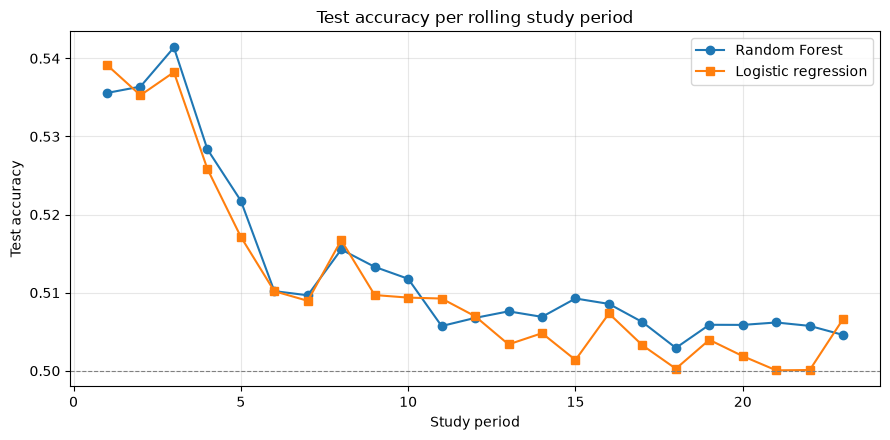

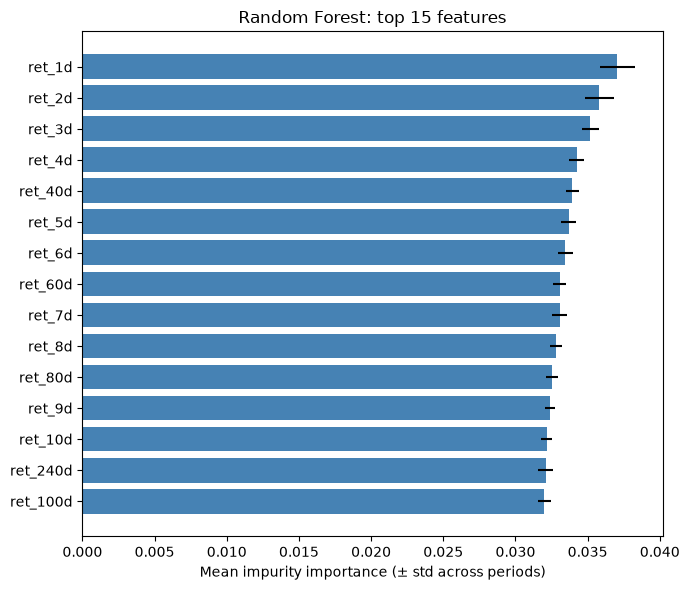

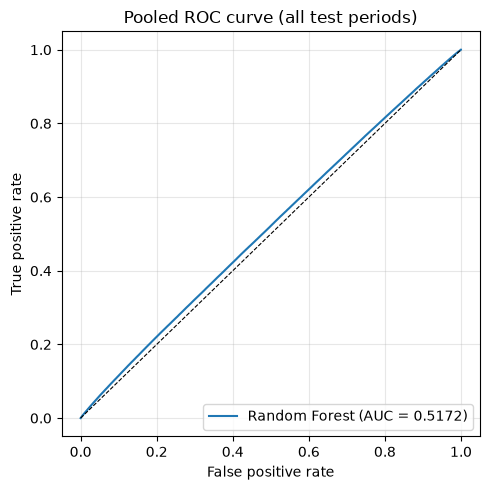

In [10]:
# 1. Test accuracy per study period: RF vs logistic regression (if available)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(rf_periods["study_period"], rf_periods["test_acc"], marker="o", label="Random Forest")
lr_summary_path = RESULTS_DIR / "rolling_all_periods_summary.csv"
if lr_summary_path.exists():
    lr_summary = pd.read_csv(lr_summary_path)
    ax.plot(lr_summary["study_period"], lr_summary["test_acc"], marker="s", label="Logistic regression")
ax.axhline(0.5, color="grey", linestyle="--", linewidth=0.8)
ax.set_xlabel("Study period")
ax.set_ylabel("Test accuracy")
ax.set_title("Test accuracy per rolling study period")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "rf_rolling_accuracy.png", dpi=150)
plt.show()

# 2. Feature importance (top 15, error bars = std across periods)
top = rf_importance_summary.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index, top["mean_importance"], xerr=top["std_importance"], color="steelblue")
ax.set_xlabel("Mean impurity importance (± std across periods)")
ax.set_title("Random Forest: top 15 features")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "rf_feature_importance.png", dpi=150)
plt.show()

# 3. Pooled ROC curve
fpr, tpr, _ = roc_curve(y_te, p_te)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr, tpr, label=f"Random Forest (AUC = {pooled['roc_auc']:.4f})")
ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("Pooled ROC curve (all test periods)")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "rf_roc_curve.png", dpi=150)
plt.show()
